# Т-Банк: Коммуникации в Городе

Задача исследования - изучить коммуникации с клиентами сервисов «Города» и особенности данных, влияющие на настройку AutoML для прогноза заказов. В исходных данных есть шесть счётчиков заказов по сервисам; единая целевая переменная и горизонт прогнозирования не заданы.

Источник: DANO, описание «Коммуникации в Городе». Расчёты и выводы представлены в `EDA_tbank_gorod_communications.md`.

Для воспроизведения нужен файл [коммуникации по Городу.csv](https://drive.google.com/file/d/1JmuG4M9BoHz6iKCFQDHNGUiBdJCjwM3j/view?usp=drive_link), размещённый рядом с ноутбуком. Используются библиотеки `pandas`, `numpy`, `matplotlib`. Ячейки выполняются сверху вниз.

## 1. Первичный анализ

Проверяются структура таблицы, типы столбцов, ключи и полнота данных. Единица наблюдения - клиент и дата, а не отдельная коммуникация.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

path = Path("коммуникации по Городу.csv")
if not path.is_file():
    raise FileNotFoundError(f"Не найден исходный файл: {path.name}")

data = pd.read_csv(path, parse_dates=["business_dt"])
services = ["ent", "super", "transport", "shopping", "hotel", "avia"]
order_cols = [f"orders_amt_{service}" for service in services]
imp_cols = [f"{channel}_imp_{service}" for channel in ("active", "passive") for service in services]
click_cols = [f"{channel}_click_{service}" for channel in ("active", "passive") for service in services]
service_names = {"ent": "Развлечения", "super": "Супермаркеты", "transport": "Транспорт",
                 "shopping": "Шопинг", "hotel": "Отели", "avia": "Авиабилеты"}

print("Размер таблицы:", data.shape)
display(data.head(3))
display(pd.DataFrame({"Тип столбца": data.dtypes.astype(str).value_counts().index,
                      "Количество": data.dtypes.astype(str).value_counts().values}))

Размер таблицы: (118189, 35)


,id,business_dt,active_imp_ent,active_click_ent,active_imp_super,active_click_super,active_imp_transport,active_click_transport,active_imp_shopping,active_click_shopping,...,passive_click_avia,orders_amt_ent,orders_amt_super,orders_amt_transport,orders_amt_shopping,orders_amt_hotel,orders_amt_avia,gender_cd,age,device_platform_cd
0,7119,2025-04-02,0.0,0.0,3.0,1.0,1.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,F,40,iOS
1,1797,2025-08-27,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,M,38,IOS
2,8010,2025-07-10,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,M,51,Android


,Тип столбца,Количество
0,int64,16
1,float64,16
2,str,2
3,datetime64[us],1


In [2]:
structure = pd.Series({
    "Строк": len(data),
    "Столбцов": data.shape[1],
    "Уникальных клиентов": data["id"].nunique(),
    "Уникальных дат": data["business_dt"].nunique(),
    "Повторов (id, business_dt)": int(data.duplicated(["id", "business_dt"]).sum()),
    "Полных дубликатов": int(data.duplicated().sum()),
    "Пропущенных ячеек": int(data.isna().sum().sum()),
}, name="Значение")
display(structure.to_frame())
print("Период:", data["business_dt"].min().date(), "—", data["business_dt"].max().date())

,Значение
Строк,118189
Столбцов,35
Уникальных клиентов,8339
Уникальных дат,284
"Повторов (id, business_dt)",0
Полных дубликатов,0
Пропущенных ячеек,0


Период: 2025-01-09 — 2025-11-04


## 2. Повторные клиенты и неполная панель

Проверяются повторяемость клиентов и интервалы между соседними датами их наблюдения. Отсутствие строки за день нельзя автоматически считать нулевой активностью.

,Значение
Клиентов с несколькими строками,8339.00
Максимум строк на клиента,52.00
Медиана строк на клиента,13.00
"Медианный промежуток между наблюдениями, дней",9.00
"Промежутков более одного дня, %",90.14
Календарных дней в интервале,300.00
Дней с наблюдениями,284.00
Дней без наблюдений,16.00


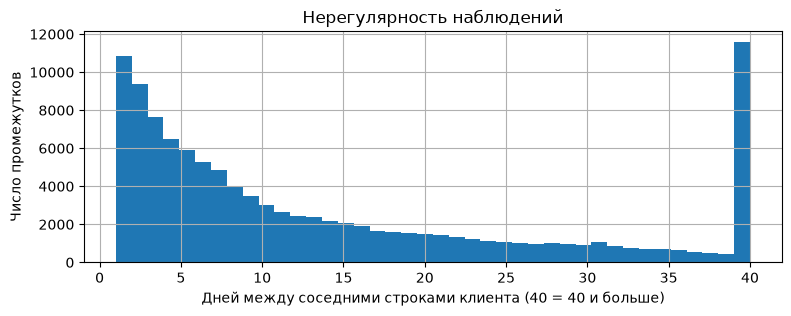

In [3]:
user_counts = data.groupby("id").size()
intervals = (data.sort_values(["id", "business_dt"])
             .groupby("id")["business_dt"].diff().dt.days.dropna())
full_days = (data["business_dt"].max() - data["business_dt"].min()).days + 1
panel_summary = pd.Series({
    "Клиентов с несколькими строками": int((user_counts > 1).sum()),
    "Максимум строк на клиента": int(user_counts.max()),
    "Медиана строк на клиента": float(user_counts.median()),
    "Медианный промежуток между наблюдениями, дней": float(intervals.median()),
    "Промежутков более одного дня, %": round(100 * (intervals > 1).mean(), 2),
    "Календарных дней в интервале": int(full_days),
    "Дней с наблюдениями": int(data["business_dt"].nunique()),
    "Дней без наблюдений": int(full_days - data["business_dt"].nunique()),
}, name="Значение")
display(panel_summary.to_frame())
fig, ax = plt.subplots(figsize=(9, 3))
intervals.clip(upper=40).hist(bins=40, ax=ax)
ax.set(xlabel="Дней между соседними строками клиента (40 = 40 и больше)",
       ylabel="Число промежутков", title="Нерегулярность наблюдений")
plt.show()

## 3. Число заказов и возможные целевые переменные

Для каждого сервиса доступно количество заказов в строке клиента. Проверяются частоты нулевых и положительных исходов, редкость заказов и одновременные заказы в нескольких сервисах. Выбор целевого сервиса и горизонта здесь не производится.

,Значение
Строк хотя бы с одним заказом,10990.0
"Доля строк с заказами, %",9.3
Суммарное число заказов,12439.0
Строк с заказами в нескольких сервисах,392.0
Максимум заказов в строке,11.0


,Сервис,Строк с заказами,"Доля строк, %",Заказов всего,Максимум за строку
0,Развлечения,1055,0.89,1182,11
1,Супермаркеты,2421,2.05,2574,4
2,Транспорт,5871,4.97,6280,5
3,Шопинг,737,0.62,904,11
4,Отели,430,0.36,464,3
5,Авиабилеты,882,0.75,1035,6


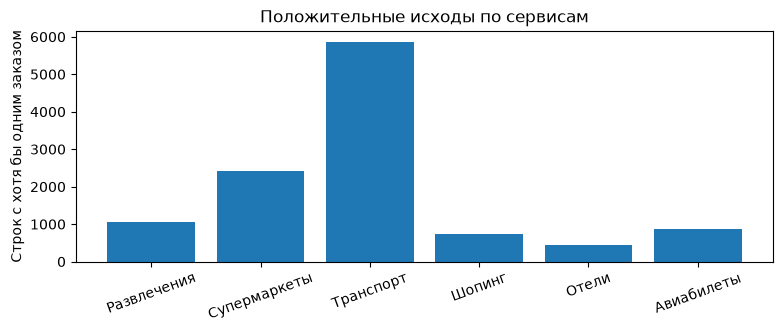

In [4]:
row_orders = data[order_cols].sum(axis=1)
any_order = row_orders.gt(0)
order_summary = pd.Series({
    "Строк хотя бы с одним заказом": int(any_order.sum()),
    "Доля строк с заказами, %": round(100 * any_order.mean(), 2),
    "Суммарное число заказов": int(row_orders.sum()),
    "Строк с заказами в нескольких сервисах": int((data[order_cols].gt(0).sum(axis=1) > 1).sum()),
    "Максимум заказов в строке": int(row_orders.max()),
}, name="Значение")
display(order_summary.to_frame())
order_by_service = pd.DataFrame([
    {"Сервис": service_names[s], "Строк с заказами": int(data[f"orders_amt_{s}"].gt(0).sum()),
     "Доля строк, %": round(100 * data[f"orders_amt_{s}"].gt(0).mean(), 2),
     "Заказов всего": int(data[f"orders_amt_{s}"].sum()),
     "Максимум за строку": int(data[f"orders_amt_{s}"].max())}
    for s in services
])
display(order_by_service)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(order_by_service["Сервис"], order_by_service["Строк с заказами"])
ax.set(ylabel="Строк с хотя бы одним заказом", title="Положительные исходы по сервисам")
ax.tick_params(axis="x", rotation=20)
plt.show()

## 4. Активные и пассивные коммуникации

Для шести сервисов изучаются показы и клики двух типов коммуникаций. Несогласованность счётчиков не исправляется автоматически, поскольку неизвестна точная методика их подсчёта.

In [5]:
comm_rows = []
for channel in ("active", "passive"):
    for s in services:
        imp = data[f"{channel}_imp_{s}"]
        click = data[f"{channel}_click_{s}"]
        comm_rows.append({
            "Канал": channel, "Сервис": service_names[s],
            "Показов": int(imp.sum()), "Кликов": int(click.sum()),
            "Строк с кликами > показов": int((click > imp).sum()),
            "Строк с кликами и без показов": int(((click > 0) & imp.eq(0)).sum()),
        })
comm_summary = pd.DataFrame(comm_rows)
display(comm_summary)
print("Всего сочетаний с кликами больше показов:", int(comm_summary["Строк с кликами > показов"].sum()))
print("Всего сочетаний с кликами при нулевых показах:", int(comm_summary["Строк с кликами и без показов"].sum()))

,Канал,Сервис,Показов,Кликов,Строк с кликами > показов,Строк с кликами и без показов
0,active,Развлечения,37103,28399,3789,3294
1,active,Супермаркеты,44939,32569,6176,5606
2,active,Транспорт,67877,52353,9623,8256
3,active,Шопинг,30088,23481,3388,3003
4,active,Отели,16688,4167,0,0
5,active,Авиабилеты,22800,6370,0,0
6,passive,Развлечения,65268,3223,77,43
7,passive,Супермаркеты,33042,1049,76,10
8,passive,Транспорт,93796,2409,47,17
9,passive,Шопинг,81396,1282,88,27


Всего сочетаний с кликами больше показов: 23567
Всего сочетаний с кликами при нулевых показах: 20524


,Показов,Кликов
Канал,,
active,219495,147339
passive,473140,18097


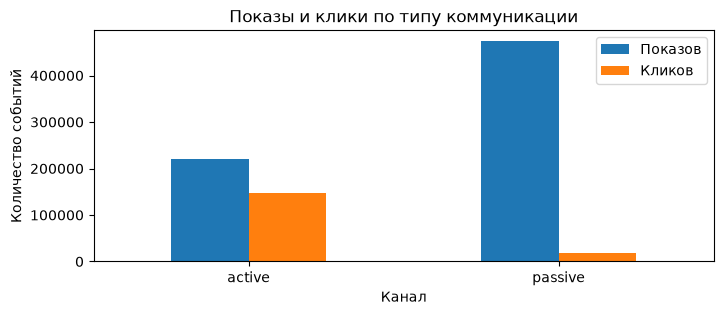

In [6]:
channel_totals = (comm_summary.groupby("Канал")[["Показов", "Кликов"]].sum())
display(channel_totals)
ax = channel_totals.plot.bar(figsize=(8, 3), rot=0)
ax.set(ylabel="Количество событий", title="Показы и клики по типу коммуникации")
plt.show()

## 5. Пропуски, типы и специальные значения

Проверяются скрытые различия категориальных значений, возраст и арифметическая корректность счётчиков. Отсутствие стандартных пропусков не означает, что все данные однозначно интерпретируемы.

In [7]:
display(data["device_platform_cd"].value_counts().rename_axis("Платформа").to_frame("Строк"))
display(data["gender_cd"].value_counts().rename_axis("Пол").to_frame("Строк"))
count_cols = imp_cols + click_cols + order_cols
quality_summary = pd.Series({
    "Стандартных пропусков": int(data.isna().sum().sum()),
    "Отрицательных счётчиков": int(data[count_cols].lt(0).sum().sum()),
    "Дробных непустых счётчиков": int((data[count_cols].mod(1).ne(0) & data[count_cols].notna()).sum().sum()),
    "Минимальный возраст": int(data["age"].min()),
    "Максимальный возраст": int(data["age"].max()),
    "Строк с возрастом менее 18": int(data["age"].lt(18).sum()),
}, name="Значение")
display(quality_summary.to_frame())

,Строк
Платформа,
Android,55232
iOS,47637
IOS,14042
iPadOS,1278


,Строк
Пол,
M,81030
F,37159


,Значение
Стандартных пропусков,0
Отрицательных счётчиков,0
Дробных непустых счётчиков,0
Минимальный возраст,15
Максимальный возраст,80
Строк с возрастом менее 18,225


In [8]:
per_id = data.groupby("id")
stability = pd.DataFrame({
    "Поле": ["gender_cd", "age", "device_platform_cd"],
    "Клиентов с несколькими значениями": [int(per_id[c].nunique().gt(1).sum())
                                              for c in ("gender_cd", "age", "device_platform_cd")]
})
display(stability)

,Поле,Клиентов с несколькими значениями
0,gender_cd,0
1,age,0
2,device_platform_cd,0


## 6. Связь коммуникаций с заказами

Описываются совпадения кликов и заказов в одной строке и различия частот заказов между группами. Это не оценка влияния коммуникаций: покупки могут происходить позже, а группы не формировались случайным назначением.

In [9]:
click_any = data[click_cols].sum(axis=1).gt(0)
print("Строк, в которых нет ни одного клика по всем сервисам:", int((~click_any).sum()))
service_association = []
for s in services:
    service_clicked = (data[f"active_click_{s}"] + data[f"passive_click_{s}"]).gt(0)
    service_ordered = data[f"orders_amt_{s}"].gt(0)
    service_association.append({
        "Сервис": service_names[s],
        "Без кликов по сервису": int((~service_clicked).sum()),
        "Заказов без кликов по сервису": int((service_ordered & ~service_clicked).sum()),
        "Заказы без кликов, %": round(100 * service_ordered[~service_clicked].mean(), 2),
        "Строк с кликами по сервису": int(service_clicked.sum()),
        "Заказы с кликами, %": round(100 * service_ordered[service_clicked].mean(), 2),
    })
display(pd.DataFrame(service_association))

Строк, в которых нет ни одного клика по всем сервисам: 0


,Сервис,Без кликов по сервису,Заказов без кликов по сервису,"Заказы без кликов, %",Строк с кликами по сервису,"Заказы с кликами, %"
0,Развлечения,89800,372,0.41,28389,2.41
1,Супермаркеты,89689,1613,1.80,28500,2.84
2,Транспорт,72570,2735,3.77,45619,6.87
3,Шопинг,95877,439,0.46,22312,1.34
4,Отели,107581,321,0.30,10608,1.03
5,Авиабилеты,108931,708,0.65,9258,1.88


## 7. Временная структура и изменения доли заказов

Проверяются месячные изменения состава наблюдений и частоты заказов. Январь и ноябрь представлены неполностью и не сопоставляются с полными месяцами без оговорок.

,Строк,Строк_с_заказом,"Доля заказов, %"
Месяц,,,
2025-01,71,10,14.08
2025-02,10226,882,8.63
2025-03,8105,679,8.38
2025-04,13770,1182,8.58
2025-05,21843,2163,9.90
2025-06,12445,1227,9.86
2025-07,12561,1526,12.15
2025-08,12867,1298,10.09
2025-09,11170,939,8.41


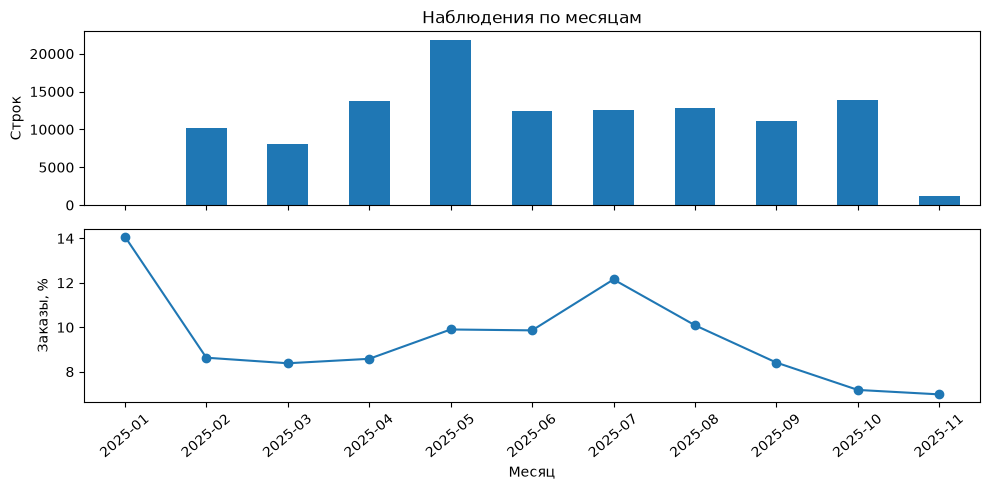

In [10]:
monthly = pd.DataFrame({"Месяц": data["business_dt"].dt.to_period("M").astype(str),
                        "Заказ": any_order.astype(int)}).groupby("Месяц").agg(
                            Строк=("Заказ", "size"),
                            Строк_с_заказом=("Заказ", "sum"),
                            Доля_заказов=("Заказ", "mean"))
monthly["Доля заказов, %"] = (monthly.pop("Доля_заказов") * 100).round(2)
display(monthly)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
monthly["Строк"].plot.bar(ax=axes[0]); axes[0].set(ylabel="Строк", title="Наблюдения по месяцам")
monthly["Доля заказов, %"].plot(ax=axes[1], marker="o"); axes[1].set(ylabel="Заказы, %", xlabel="Месяц")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

## 8. Временное разделение и повторные клиенты

Иллюстративная граница `2025-09-01` отделяет более поздние наблюдения. Оцениваются размеры двух периодов, частоты заказов и повторные клиенты. Это не готовая валидация будущих заказов без определения горизонта метки.

In [11]:
border = pd.Timestamp("2025-09-01")
earlier = data["business_dt"].lt(border)
validation_preview = pd.DataFrame([
    {"Период": "До 2025-09-01", "Строк": int(earlier.sum()),
     "Клиентов": int(data.loc[earlier, "id"].nunique()),
     "Строк с заказом": int(any_order[earlier].sum()),
     "Доля заказов, %": round(100 * any_order[earlier].mean(), 2)},
    {"Период": "С 2025-09-01", "Строк": int((~earlier).sum()),
     "Клиентов": int(data.loc[~earlier, "id"].nunique()),
     "Строк с заказом": int(any_order[~earlier].sum()),
     "Доля заказов, %": round(100 * any_order[~earlier].mean(), 2)},
])
display(validation_preview)
common_ids = set(data.loc[earlier, "id"]) & set(data.loc[~earlier, "id"])
print("Общих клиентов в двух периодах:", len(common_ids))

,Период,Строк,Клиентов,Строк с заказом,"Доля заказов, %"
0,До 2025-09-01,91888,8332,8967,9.76
1,С 2025-09-01,26301,7252,2023,7.69


Общих клиентов в двух периодах: 7245


## 9. Постановка цели и ограничения доступности признаков

Число заказов `orders_amt_*` допускает две разные постановки для выбранного сервиса: классификацию наличия заказа или регрессию числа заказов. Сумма по шести сервисам также может быть описательным показателем, но не становится автоматически согласованной целевой переменной.

Для прогноза до отправки коммуникации недоступны фактические показы, клики и заказы текущего дня. Для прогноза после коммуникации необходимо установить порядок событий внутри дня. В CSV есть только дата `business_dt`, но нет времени конкретного показа, клика или заказа. Поэтому нельзя доказать, что признак был известен до целевого события.

Покупка может произойти спустя несколько дней после коммуникации. Поскольку записи клиента по календарю нерегулярны, отсутствие строки за следующий день не является подтверждённым отсутствием заказа. Построение будущей метки на фиксированный горизонт без уточнения правил регистрации событий было бы предположением.

Таблица позволяет описать наблюдаемые исходы и связи, но не позволяет по ним оценить причинный эффект отправки коммуникации.

## 10. Выводы для настройки AutoML

1. Уточнять конкретный сервис, прогнозируемое событие и горизонт: шесть столбцов `orders_amt_*` не задают единственного таргета.
2. Различать классификацию наличия заказа и регрессию количества заказов; частоты положительных наблюдений различаются по сервисам.
3. Не формировать будущие отрицательные метки из пропущенных дат клиента без подтверждения полноты наблюдения.
4. Исключать признаки коммуникаций и заказов, появившиеся после момента прогноза; временная доступность внутри дня не подтверждена.
5. Для будущих периодов рассматривать хронологическую проверку, а для новых клиентов - отдельное групповое разделение.
6. Нормализовывать `iOS` и `IOS`, не приравнивать клики к показам и не исправлять противоречивые счётчики без документации.
7. Не интерпретировать корреляцию коммуникаций и заказов как доказанный эффект контакта на покупку.